In [1]:
import sys, json, warnings, io, unittest
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from src.evaluation import segments as S, temporal as TP, final_evaluation as E, intervals as V, feature_selection as F
from src.evaluation.run_feature_selection import load
from src.features import preprocessing as P
from src.features.feature_sets import REDUCED_DROP

pd.set_option('display.width', 230, 'display.max_columns', 45, 'display.max_rows', 150, 'display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True); TAB = ROOT / 'reports' / 'tables'
TP.run_all()                                                         # no-op when cached
df, X, y, folds = load()
O = S.build_eval_frame()
O['price_actual'] = pd.cut(O.y, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
O['price_pred'] = pd.cut(O.pred, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
O['flagged'] = O.Id.isin(E.FLAGGED_IDS)
G = O[O.model == 'gbr_tuned']; G0 = G[G.repeat == 0]; Gx = G[~G.flagged]; G0x = G0[~G0.flagged]
N0 = O[(O.model == 'enet_tuned') & (O.repeat == 0)]
COLS = ['n', 'log_rmse', 'mae', 'median_ae', 'rmse_usd', 'mape', 'signed_usd', 'signed_log', 'sd_log_resid']
FMT = {'n': 0, 'log_rmse': 3, 'mae': 0, 'median_ae': 0, 'rmse_usd': 0, 'mape': 2, 'signed_usd': 0, 'signed_log': 3, 'sd_log_resid': 3, 'mean_actual': 0, 'mean_pred': 0}
TEMP_META = json.loads((TP.OUT / 'run_metadata.json').read_text())
print(len(O), 'rows =', O.row.nunique(), 'houses x 3 repeats x 2 models | primary model: tuned Gradient Boosting (06 working model)')

8760 rows = 1460 houses x 3 repeats x 2 models | primary model: tuned Gradient Boosting (03d working model)


In [2]:
SEG = {}

In [3]:
tab = S.segment_table(O, 'gbr_tuned', 'price_actual')
tab = S.with_ci(tab, G0, 'price_actual')
cls = S.seg_vs_rest(G0, 'price_actual')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Retrospective: actual-price band (diagnostic only; cannot be used for live decisions)')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['price_actual'] = out

tab = S.segment_table(O, 'gbr_tuned', 'price_pred')
tab = S.with_ci(tab, G0, 'price_pred')
cls = S.seg_vs_rest(G0, 'price_pred')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Deployable: predicted-price band')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['price_pred'] = out

Retrospective: actual-price band (diagnostic only; cannot be used for live decisions)


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
price_actual,,,,,,,,,,,,,,,,,,,
low,365.0,0.159,10928.0,7639.0,15642.0,11.75,-4595.0,-0.044,0.153,0.139,0.180,10193.0,12497.0,10.54,13.52,-6512.0,-3444.0,0.042,supported + practical
mid,951.0,0.108,13805.0,9233.0,23662.0,7.43,538.0,0.008,0.108,0.094,0.139,12774.0,16006.0,6.87,8.66,-1387.0,2225.0,-0.038,supported + practical
luxury,144.0,0.145,38638.0,26887.0,58462.0,9.94,24104.0,0.064,0.131,0.111,0.157,30513.0,42546.0,8.32,10.68,13858.0,29816.0,0.005,practical only


Deployable: predicted-price band


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
price_pred,,,,,,,,,,,,,,,,,,,
low,371.0,0.150,10280.0,7530.0,14076.0,10.63,972.0,-0.001,0.150,0.128,0.166,9366.0,11318.0,9.35,11.94,-348.0,2487.0,0.025,practical only
mid,947.0,0.103,13563.0,9471.0,19847.0,7.38,1289.0,0.002,0.103,0.095,0.113,12859.0,14681.0,7.02,8.06,122.0,2607.0,-0.062,supported + practical
luxury,142.0,0.189,42402.0,27374.0,69202.0,13.06,5045.0,-0.003,0.190,0.123,0.285,33089.0,53897.0,9.43,20.14,-12950.0,12082.0,0.090,practical only


In [4]:
print('Sensitivity: the same two views without the two flagged houses (Ids 524 and 1299, both predicted luxury and both over-predicted by about $450k); evaluation-only exclusion')
for by in ['price_actual', 'price_pred']:
    t = S.segment_table(Gx.assign(model='gbr_tuned'), 'gbr_tuned', by); print(by); display(t[COLS].round(FMT))
print('Actual-price band, ElasticNet (tuned) for comparison'); display(S.segment_table(O, 'enet_tuned', 'price_actual')[COLS].round(FMT))
print('Absolute vs relative error: median APE %% and MAE by band (deployable view)'); display(pd.concat({'MAE USD': S.segment_table(O, 'gbr_tuned', 'price_pred').mae, 'median APE %': S.segment_table(O, 'gbr_tuned', 'price_pred').median_ape}, axis=1).round(1))

Sensitivity: the same two views without the two flagged houses (Ids 524 and 1299, both predicted luxury and both over-predicted by about $450k); evaluation-only exclusion
price_actual


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
price_actual,,,,,,,,,
low,365.0,0.159,10928.0,7639.0,15642.0,11.75,-4595.0,-0.044,0.153
mid,949.0,0.098,13222.0,9204.0,19031.0,7.09,1151.0,0.010,0.098
luxury,144.0,0.145,38638.0,26887.0,58462.0,9.94,24104.0,0.064,0.131


price_pred


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
price_pred,,,,,,,,,
low,371.0,0.150,10280.0,7530.0,14076.0,10.63,972.0,-0.001,0.150
mid,947.0,0.103,13563.0,9471.0,19847.0,7.38,1289.0,0.002,0.103
luxury,140.0,0.149,38833.0,26936.0,58415.0,10.82,9292.0,0.011,0.149


Actual-price band, ElasticNet (tuned) for comparison


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
price_actual,,,,,,,,,
low,365.0,0.156,10580.0,7529.0,15080.0,11.36,-3356.0,-0.034,0.152
mid,951.0,0.118,14234.0,9788.0,34901.0,7.91,-1713.0,-0.002,0.119
luxury,144.0,0.152,42669.0,29804.0,60923.0,10.84,35229.0,0.095,0.119


Absolute vs relative error: median APE %% and MAE by band (deployable view)


,MAE USD,median APE %
price_pred,,
low,10279.8,6.9
mid,13563.3,5.3
luxury,42402.4,8.1


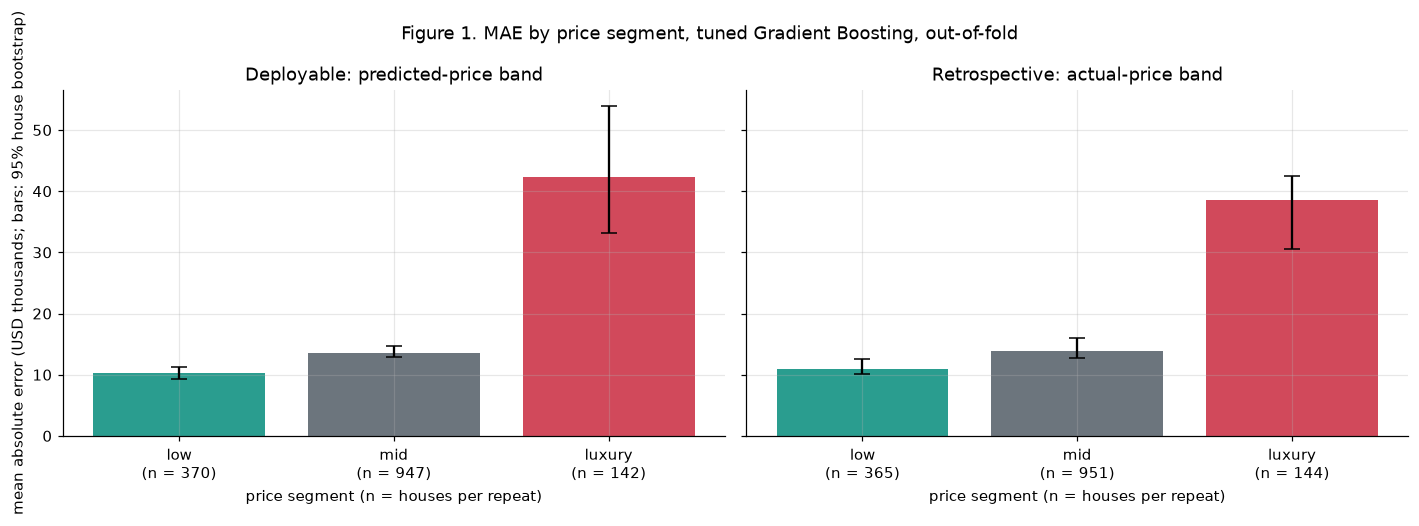

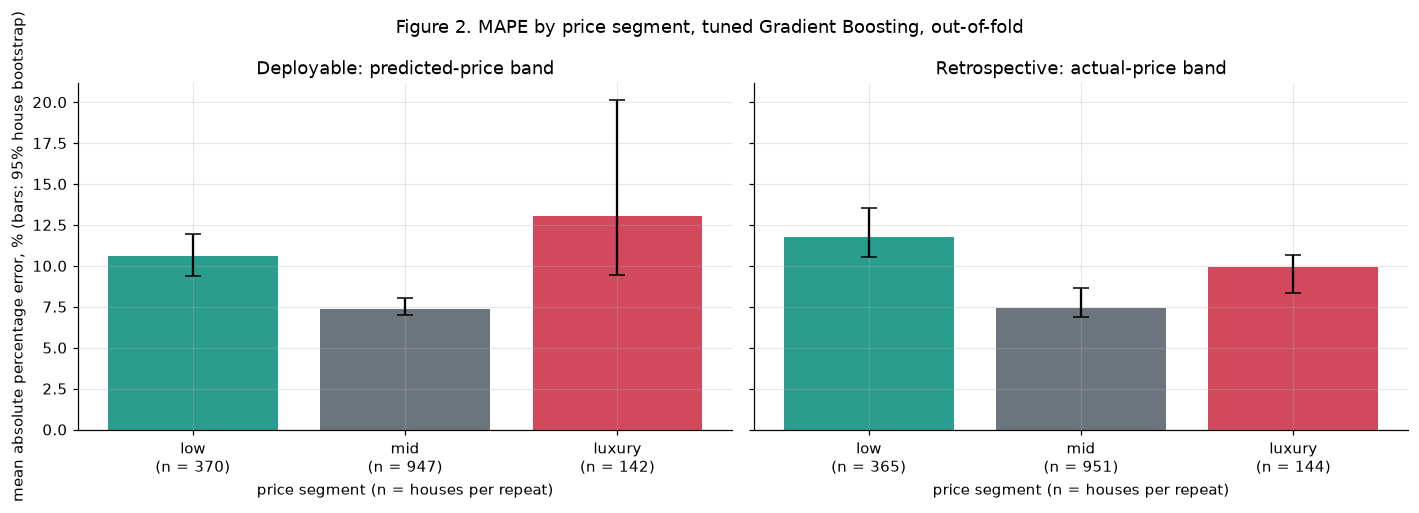

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
order = ['low', 'mid', 'luxury']
for ax, by, ttl in zip(axes, ['price_pred', 'price_actual'], ['Deployable: predicted-price band', 'Retrospective: actual-price band']):
    t = SEG[by].loc[order]
    ax.bar(range(3), t.mae / 1e3, yerr=[(t.mae - t.mae_lo) / 1e3, (t.mae_hi - t.mae) / 1e3], color=['#2a9d8f', '#6c757d', '#d1495b'], capsize=5)
    ax.set_xticks(range(3)); ax.set_xticklabels([f'{o}\n(n = {int(t.loc[o, "n"])})' for o in order]); ax.set_xlabel('price segment (n = houses per repeat)'); ax.set_title(ttl)
axes[0].set_ylabel('mean absolute error (USD thousands; bars: 95% house bootstrap)')
fig.suptitle('Figure 1. MAE by price segment, tuned Gradient Boosting, out-of-fold'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig1_mae_price.png'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, by, ttl in zip(axes, ['price_pred', 'price_actual'], ['Deployable: predicted-price band', 'Retrospective: actual-price band']):
    t = SEG[by].loc[order]
    ax.bar(range(3), t.mape, yerr=[t.mape - t.mape_lo, t.mape_hi - t.mape], color=['#2a9d8f', '#6c757d', '#d1495b'], capsize=5)
    ax.set_xticks(range(3)); ax.set_xticklabels([f'{o}\n(n = {int(t.loc[o, "n"])})' for o in order]); ax.set_xlabel('price segment (n = houses per repeat)'); ax.set_title(ttl)
axes[0].set_ylabel('mean absolute percentage error, % (bars: 95% house bootstrap)')
fig.suptitle('Figure 2. MAPE by price segment, tuned Gradient Boosting, out-of-fold'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig2_mape_price.png'); plt.show()

In [6]:
tab = S.segment_table(O, 'gbr_tuned', 'quality_tier')
tab = S.with_ci(tab, G0, 'quality_tier')
cls = S.seg_vs_rest(G0, 'quality_tier')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Quality tier (EDA F23 tiers)')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['quality_tier'] = out

Quality tier (EDA F23 tiers)


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
quality_tier,,,,,,,,,,,,,,,,,,,
low (1-4),141.0,0.185,12275.0,9079.0,16099.0,13.8,1533.0,-0.00,0.185,0.147,0.209,10657.0,14049.0,11.25,16.17,-1593.0,3697.0,0.055,supported + practical
medium (5-8),1258.0,0.110,14165.0,9339.0,21438.0,7.9,1055.0,0.00,0.110,0.102,0.120,13363.0,15030.0,7.49,8.48,-11.0,2380.0,-0.097,supported + practical
high (9-10),61.0,0.229,51321.0,24540.0,91381.0,14.7,12493.0,0.01,0.230,0.112,0.397,34483.0,77858.0,8.31,31.08,-25578.0,25763.0,0.146,practical only


In [7]:
print('Without the two flagged houses (both OverallQual 10):'); display(S.segment_table(Gx, 'gbr_tuned', 'quality_tier')[COLS].round(FMT))
rows = []
for lab, d in [('all houses', G0), ('without Ids 524, 1299', G0x)]:
    groups = [d[d.quality_tier == t].residual_log.values for t in S.QUALITY_BINS[1]]
    rows.append({'sample': lab, 'Levene p (equal log-residual SD across tiers)': stats.levene(*groups)[1], 'SD low': groups[0].std(ddof=1), 'SD medium': groups[1].std(ddof=1), 'SD high': groups[2].std(ddof=1)})
display(pd.DataFrame(rows).set_index('sample').round(4))
rng = np.random.default_rng(0); sd_ci = {}
for t_ in S.QUALITY_BINS[1]:
    r = G0[G0.quality_tier == t_].residual_log.values; sd_ci[t_] = np.percentile([r[rng.integers(0, len(r), len(r))].std(ddof=1) for _ in range(2000)], [2.5, 97.5])
print('95% bootstrap interval of the log-residual SD by tier:', {k: tuple(np.round(v, 3)) for k, v in sd_ci.items()})
print('ElasticNet (tuned) log-residual SD by tier:', N0.groupby('quality_tier', observed=True).residual_log.std().round(3).to_dict())

Without the two flagged houses (both OverallQual 10):


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
quality_tier,,,,,,,,,
low (1-4),141.0,0.185,12275.0,9079.0,16099.0,13.80,1533.0,-0.000,0.185
medium (5-8),1258.0,0.110,14165.0,9339.0,21438.0,7.90,1055.0,0.000,0.110
high (9-10),59.0,0.147,43217.0,22675.0,72339.0,9.48,22759.0,0.043,0.142


,Levene p (equal log-residual SD across tiers),SD low,SD medium,SD high
sample,,,,
all houses,0.0,0.178,0.1108,0.2672
"without Ids 524, 1299",0.0,0.178,0.1108,0.1203


95% bootstrap interval of the log-residual SD by tier: {'low (1-4)': (np.float64(0.146), np.float64(0.208)), 'medium (5-8)': (np.float64(0.102), np.float64(0.119)), 'high (9-10)': (np.float64(0.107), np.float64(0.395))}
ElasticNet (tuned) log-residual SD by tier: {'low (1-4)': 0.167, 'medium (5-8)': 0.108, 'high (9-10)': 0.329}


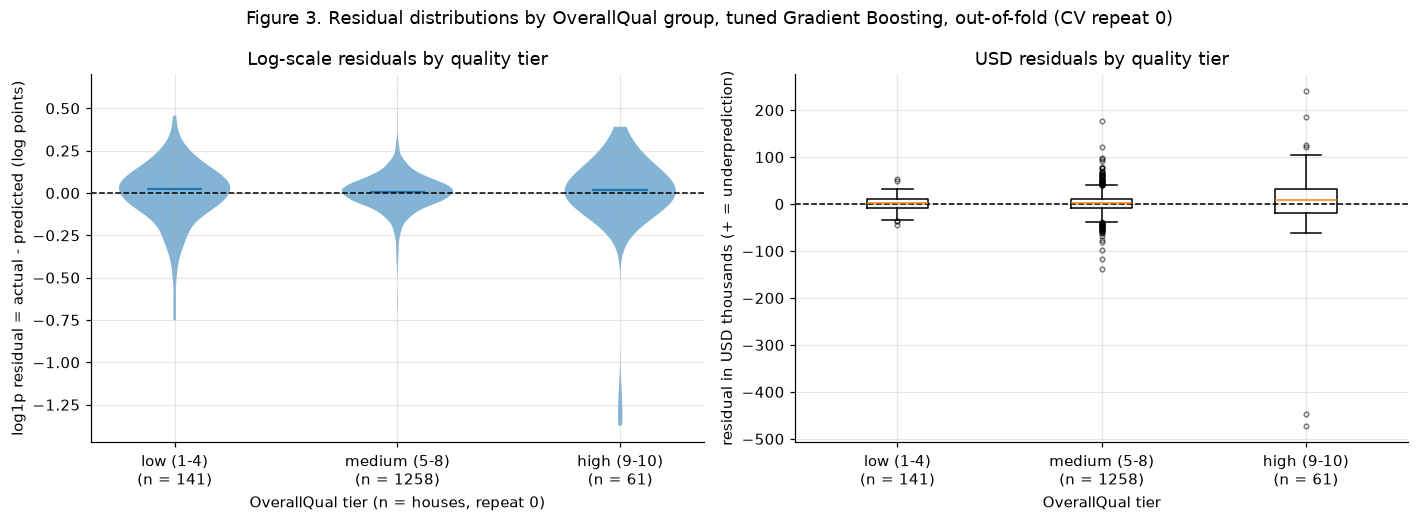

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
tiers = S.QUALITY_BINS[1]
data = [G0[G0.quality_tier == t].residual_log.values for t in tiers]
vp = axes[0].violinplot(data, showmedians=True, showextrema=False)
for b in vp['bodies']: b.set_alpha(.55)
axes[0].axhline(0, color='k', ls='--', lw=1); axes[0].set_xticks(range(1, 4)); axes[0].set_xticklabels([f'{t}\n(n = {len(d)})' for t, d in zip(tiers, data)]); axes[0].set_xlabel('OverallQual tier (n = houses, repeat 0)')
axes[0].set_ylabel('log1p residual = actual - predicted (log points)'); axes[0].set_title('Log-scale residuals by quality tier')
datau = [G0[G0.quality_tier == t].residual_usd.values / 1e3 for t in tiers]
axes[1].boxplot(datau, showfliers=True, flierprops=dict(markersize=3, alpha=.5)); axes[1].axhline(0, color='k', ls='--', lw=1); axes[1].set_xticks(range(1, 4)); axes[1].set_xticklabels([f'{t}\n(n = {len(d)})' for t, d in zip(tiers, datau)]); axes[1].set_xlabel('OverallQual tier')
axes[1].set_ylabel('residual in USD thousands (+ = underprediction)'); axes[1].set_title('USD residuals by quality tier')
fig.suptitle('Figure 3. Residual distributions by OverallQual group, tuned Gradient Boosting, out-of-fold (CV repeat 0)'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig3_quality_residuals.png'); plt.show()

In [9]:
MIN_N = S.MIN_N_NEIGHBORHOOD
cnt = G0.Neighborhood.value_counts()
nb = S.segment_table(O, 'gbr_tuned', 'Neighborhood')
nb = S.with_ci(nb, G0, 'Neighborhood')
iv = S.interval_segment_table(O, 'Neighborhood')
nbt = nb[['n', 'mean_actual', 'mean_pred', 'mae', 'mae_lo', 'mae_hi', 'rmse_usd', 'mape', 'mape_lo', 'mape_hi', 'signed_usd', 'median_ae', 'log_rmse']].join(iv[['coverage', 'mean_width_usd', 'median_rel_width_pct']])
nbt['detailed (n>=30)'] = nbt.n >= MIN_N
big = nbt[nbt['detailed (n>=30)']].sort_values('mape')
print(f'Detailed neighbourhood comparison (n >= {MIN_N} houses): {len(big)} neighbourhoods, {int(big.n.sum())} of 1,460 houses')
display(big.round({'n': 0, 'mean_actual': 0, 'mean_pred': 0, 'mae': 0, 'mae_lo': 0, 'mae_hi': 0, 'rmse_usd': 0, 'mape': 2, 'mape_lo': 2, 'mape_hi': 2, 'signed_usd': 0, 'median_ae': 0, 'log_rmse': 3, 'coverage': 3, 'mean_width_usd': 0, 'median_rel_width_pct': 1}))
print('Supplementary: small neighbourhoods (n < 30), listed but NOT ranked; estimates are very noisy'); display(nbt[~nbt['detailed (n>=30)']].sort_values('n', ascending=False)[['n', 'mean_actual', 'mean_pred', 'mae', 'rmse_usd', 'mape', 'signed_usd', 'median_ae']].round(FMT))
nbt.round(4).to_csv(TAB / 'segments_neighborhood.csv')
sp = stats.spearmanr(nbt.n[nbt.n >= 10], nbt.mape[nbt.n >= 10]); sp2 = stats.spearmanr(nbt.n[nbt.n >= 10], nbt.log_rmse[nbt.n >= 10])
print(f'Spearman(neighbourhood size, MAPE) over {int((nbt.n >= 10).sum())} neighbourhoods with n >= 10: {sp[0]:.2f} (p = {sp[1]:.2f}); with Log-RMSE: {sp2[0]:.2f} (p = {sp2[1]:.2f})  [descriptive; 21 points]')
sp3 = stats.spearmanr(nbt.mean_actual[nbt.n >= 10], nbt.mape[nbt.n >= 10]); print(f'Spearman(mean price, MAPE) = {sp3[0]:.2f} (p = {sp3[1]:.2f})')
d = seg_cls = S.seg_vs_rest(G0[G0.Neighborhood.isin(big.index)], 'Neighborhood')
print('Neighbourhoods whose Log-RMSE differs from the rest (Bonferroni-adjusted):'); display(d[d['class'] != 'descriptive only'][['n', 'logrmse_diff_vs_rest', 'adj_ci_lo', 'adj_ci_hi', 'class']].round(3))

Detailed neighbourhood comparison (n >= 30 houses): 16 neighbourhoods, 1310 of 1,460 houses


,n,mean_actual,mean_pred,mae,mae_lo,mae_hi,rmse_usd,mape,mape_lo,mape_hi,signed_usd,median_ae,log_rmse,coverage,mean_width_usd,median_rel_width_pct,detailed (n>=30)
Neighborhood,,,,,,,,,,,,,,,,,
Gilbert,79.0,192855.0,193358.0,9759.0,7640.0,11931.0,13615.0,5.07,4.02,6.27,-504.0,6352.0,0.070,0.844,39804.0,18.2,True
CollgCr,150.0,197966.0,198872.0,12561.0,10563.0,14436.0,17403.0,5.98,5.17,6.66,-906.0,8880.0,0.075,0.867,45352.0,20.8,True
SawyerW,59.0,186556.0,187739.0,11803.0,8876.0,13679.0,15623.0,6.32,4.88,7.54,-1183.0,9285.0,0.080,0.847,48037.0,22.3,True
NAmes,225.0,145847.0,146702.0,10771.0,8966.0,11855.0,16441.0,7.34,6.25,8.29,-855.0,6694.0,0.105,0.840,40606.0,24.2,True
Somerst,86.0,225380.0,220813.0,18184.0,13811.0,21504.0,26912.0,8.08,6.00,10.33,4566.0,12356.0,0.115,0.783,61669.0,24.9,True
NridgHt,77.0,316271.0,307613.0,26875.0,21516.0,34145.0,39208.0,8.12,6.86,10.08,8658.0,16541.0,0.110,0.814,127203.0,37.0,True
Timber,38.0,242247.0,242505.0,20653.0,15159.0,28164.0,29839.0,8.16,6.27,10.56,-257.0,15328.0,0.112,0.816,78986.0,29.3,True
NWAmes,73.0,189050.0,191281.0,14085.0,10965.0,18137.0,21271.0,8.20,5.72,12.04,-2231.0,8901.0,0.126,0.840,53076.0,25.2,True
Mitchel,49.0,156270.0,157349.0,12225.0,9455.0,15919.0,16855.0,8.36,6.06,11.26,-1079.0,8150.0,0.116,0.850,43958.0,23.8,True


Supplementary: small neighbourhoods (n < 30), listed but NOT ranked; estimates are very noisy


,n,mean_actual,mean_pred,mae,rmse_usd,mape,signed_usd,median_ae
Neighborhood,,,,,,,,
ClearCr,28.0,212565.0,202680.0,23695.0,30430.0,11.16,9885.0,17508.0
StoneBr,25.0,310499.0,288006.0,36758.0,54573.0,10.79,22493.0,21864.0
SWISU,25.0,142591.0,142835.0,13146.0,16618.0,9.12,-243.0,10931.0
Blmngtn,17.0,194871.0,195522.0,16010.0,20590.0,8.23,-652.0,11672.0
MeadowV,17.0,98576.0,102827.0,6094.0,7746.0,6.35,-4251.0,5740.0
BrDale,16.0,104494.0,104512.0,6681.0,7936.0,6.66,-18.0,7413.0
Veenker,11.0,238773.0,221296.0,18344.0,22497.0,7.09,17477.0,13960.0
NPkVill,9.0,142694.0,144874.0,6623.0,8792.0,4.83,-2180.0,3637.0
Blueste,2.0,137500.0,143193.0,5693.0,5926.0,4.21,-5693.0,5693.0


Spearman(neighbourhood size, MAPE) over 23 neighbourhoods with n >= 10: -0.05 (p = 0.82); with Log-RMSE: 0.05 (p = 0.81)  [descriptive; 21 points]
Spearman(mean price, MAPE) = -0.13 (p = 0.55)


Neighbourhoods whose Log-RMSE differs from the rest (Bonferroni-adjusted):


,n,logrmse_diff_vs_rest,adj_ci_lo,adj_ci_hi,class
Neighborhood,,,,,
Somerst,86,-0.021,-0.075,0.047,practical only
NAmes,225,-0.030,-0.068,0.007,practical only
IDOTRR,37,0.078,-0.025,0.192,practical only
CollgCr,150,-0.059,-0.094,-0.033,supported + practical
OldTown,113,0.031,-0.021,0.083,practical only
Gilbert,79,-0.063,-0.097,-0.032,supported + practical
Crawfor,51,0.005,-0.040,0.045,practical only
Edwards,100,0.117,-0.004,0.244,practical only
SawyerW,59,-0.054,-0.093,-0.022,supported + practical


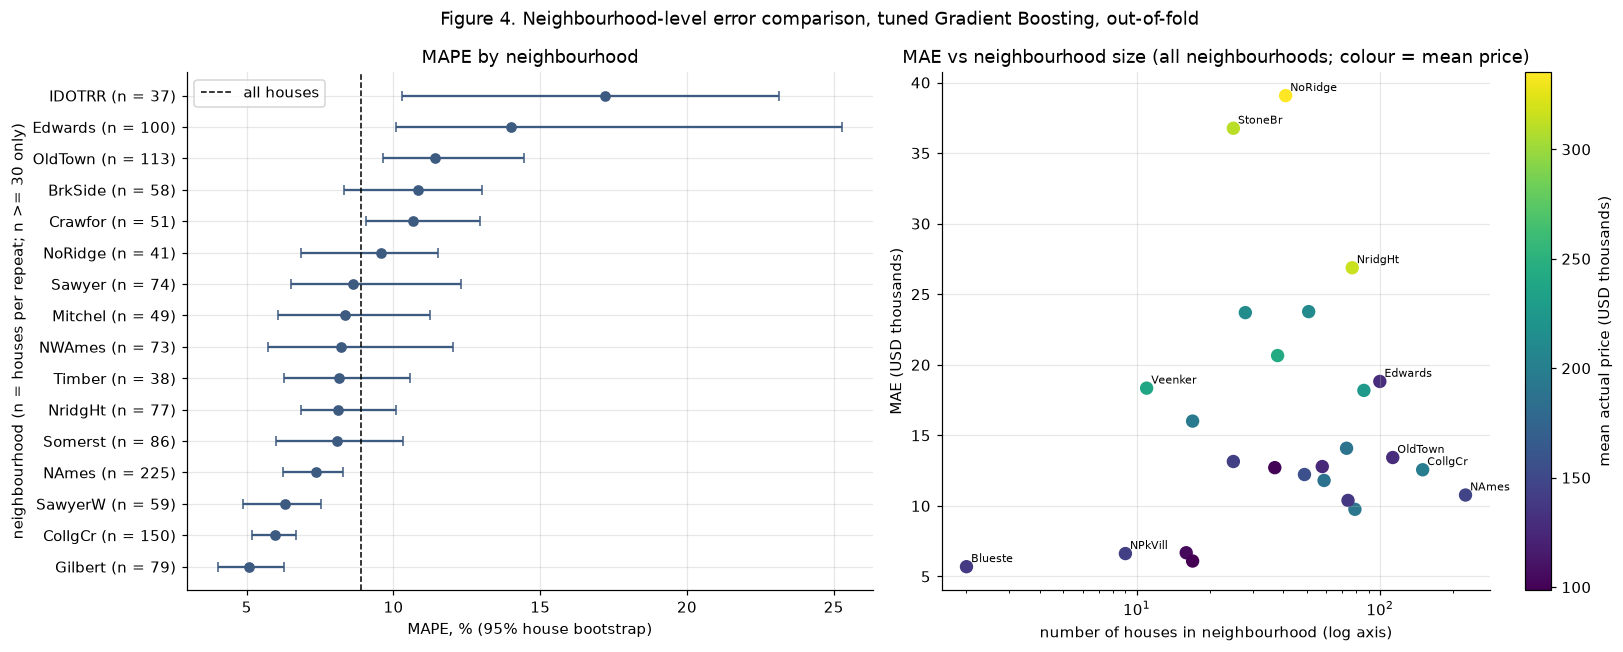

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
b = big.sort_values('mape')
axes[0].errorbar(b.mape, range(len(b)), xerr=[b.mape - b.mape_lo, b.mape_hi - b.mape], fmt='o', color='#3d5a80', capsize=3)
axes[0].axvline(G0.ape.mean() * 100, color='k', ls='--', lw=1, label='all houses'); axes[0].set_yticks(range(len(b))); axes[0].set_yticklabels([f'{i} (n = {int(n)})' for i, n in zip(b.index, b.n)])
axes[0].set_xlabel('MAPE, % (95% house bootstrap)'); axes[0].set_ylabel('neighbourhood (n = houses per repeat; n >= 30 only)'); axes[0].set_title('MAPE by neighbourhood'); axes[0].legend()
sc = axes[1].scatter(nbt.n, nbt.mae / 1e3, c=nbt.mean_actual / 1e3, s=60, cmap='viridis')
for i, r in nbt.iterrows():
    if r.n >= 100 or r.mae > 25000 or r.n < 12: axes[1].annotate(i, (r.n, r.mae / 1e3), fontsize=7, xytext=(3, 3), textcoords='offset points')
axes[1].set_xscale('log'); axes[1].set_xlabel('number of houses in neighbourhood (log axis)'); axes[1].set_ylabel('MAE (USD thousands)'); axes[1].set_title('MAE vs neighbourhood size (all neighbourhoods; colour = mean price)')
plt.colorbar(sc, ax=axes[1], label='mean actual price (USD thousands)')
fig.suptitle('Figure 4. Neighbourhood-level error comparison, tuned Gradient Boosting, out-of-fold'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig4_neighborhood.png'); plt.show()

In [11]:
tab = S.segment_table(O, 'gbr_tuned', 'age_group')
tab = S.with_ci(tab, G0, 'age_group')
cls = S.seg_vs_rest(G0, 'age_group')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Age group (HouseAge = 2010 - YearBuilt: fixed reference year, no sale information)')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['age_group'] = out

Age group (HouseAge = 2010 - YearBuilt: fixed reference year, no sale information)


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
age_group,,,,,,,,,,,,,,,,,,,
<=10 yr,388.0,0.127,20353.0,11844.0,36870.0,8.25,1755.0,0.002,0.127,0.097,0.181,17641.0,25015.0,7.00,10.86,-3765.0,4958.0,0.015,descriptive only
11-30 yr,224.0,0.101,17976.0,10954.0,35710.0,7.15,3680.0,0.005,0.101,0.080,0.102,13969.0,20027.0,6.12,7.65,-767.0,6677.0,-0.044,supported + practical
31-60 yr,530.0,0.114,11561.0,7491.0,17838.0,7.89,827.0,0.001,0.114,0.100,0.129,10519.0,12782.0,7.15,8.83,-461.0,2480.0,-0.023,practical only
>60 yr,318.0,0.158,14561.0,10532.0,20333.0,11.96,1139.0,-0.006,0.158,0.141,0.176,13540.0,16432.0,10.98,13.69,-1056.0,3380.0,0.038,supported + practical


Without the two flagged houses (built 2007-2008, in the <=10 yr group):


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
age_group,,,,,,,,,
<=10 yr,386.0,0.106,18953.0,11748.0,29591.0,7.41,3269.0,0.007,0.106
11-30 yr,224.0,0.101,17976.0,10954.0,35710.0,7.15,3680.0,0.005,0.101
31-60 yr,530.0,0.114,11561.0,7491.0,17838.0,7.89,827.0,0.001,0.114
>60 yr,318.0,0.158,14561.0,10532.0,20333.0,11.96,1139.0,-0.006,0.158


CQR interval behaviour by age group:


,n,coverage,mean_width_usd,median_rel_width_pct,cov_ci_lo,cov_ci_hi,gap_pp
age_group,,,,,,,
<=10 yr,388.0,0.817,76224.0,25.2,0.748,0.829,1.7
11-30 yr,224.0,0.833,59282.0,23.1,0.751,0.854,3.3
31-60 yr,530.0,0.811,43257.0,25.4,0.776,0.842,1.1
>60 yr,318.0,0.770,53475.0,37.8,0.721,0.813,-3.0


Spearman(house age, |log error|) = 0.139; Spearman(house age, |USD error|) = -0.095 (houses, repeat 0)


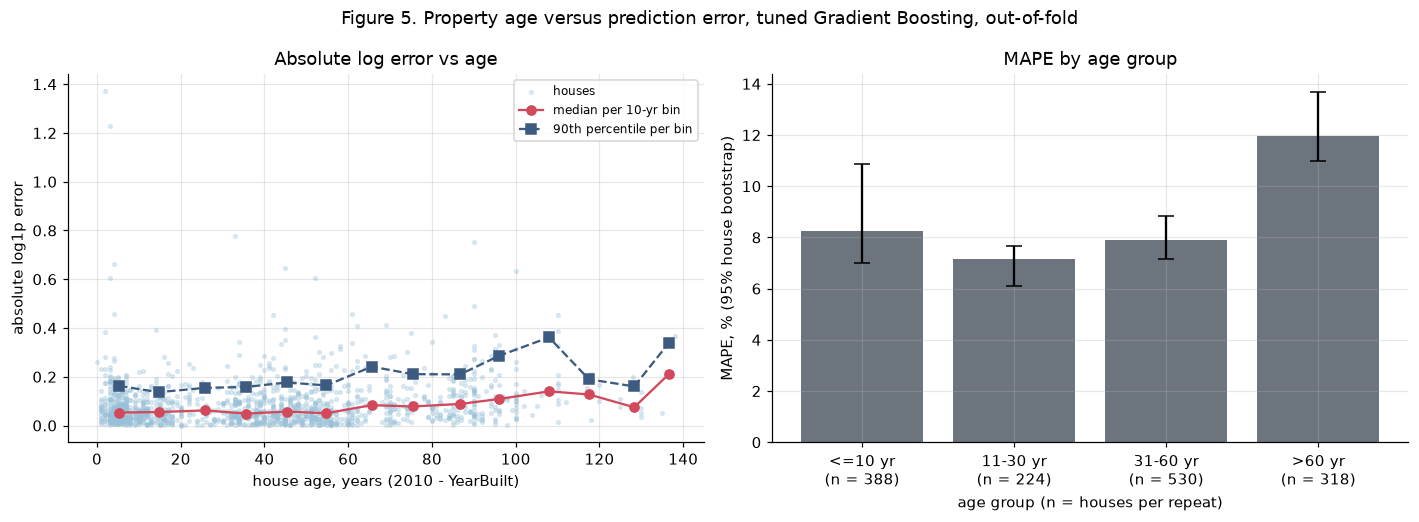

In [12]:
print('Without the two flagged houses (built 2007-2008, in the <=10 yr group):'); display(S.segment_table(Gx, 'gbr_tuned', 'age_group')[COLS].round(FMT))
iv = S.interval_segment_table(O, 'age_group'); print('CQR interval behaviour by age group:'); display(iv.round({'n': 0, 'coverage': 3, 'mean_width_usd': 0, 'median_rel_width_pct': 1, 'cov_ci_lo': 3, 'cov_ci_hi': 3, 'gap_pp': 1}))
print('Spearman(house age, |log error|) = %.3f; Spearman(house age, |USD error|) = %.3f (houses, repeat 0)' % (stats.spearmanr(G0.house_age, G0.residual_log.abs())[0], stats.spearmanr(G0.house_age, G0.abs_err_usd)[0]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bins = np.arange(0, 141, 10); G0b = G0.assign(ab=pd.cut(G0.house_age, bins, include_lowest=True))
m = G0b.groupby('ab', observed=True).agg(n=('Id', 'size'), med=('residual_log', lambda s: s.abs().median()), p90=('residual_log', lambda s: s.abs().quantile(.9)), x=('house_age', 'mean'))
axes[0].scatter(G0.house_age, G0.residual_log.abs(), s=6, alpha=.3, color='#98c1d9', label='houses'); axes[0].plot(m.x, m.med, 'o-', color='#d1495b', label='median per 10-yr bin'); axes[0].plot(m.x, m.p90, 's--', color='#3d5a80', label='90th percentile per bin')
axes[0].set_xlabel('house age, years (2010 - YearBuilt)'); axes[0].set_ylabel('absolute log1p error'); axes[0].set_title('Absolute log error vs age'); axes[0].legend(fontsize=8)
t = SEG['age_group']; ag = S.AGE_BINS[1]
axes[1].bar(range(4), t.loc[ag].mape, yerr=[t.loc[ag].mape - t.loc[ag].mape_lo, t.loc[ag].mape_hi - t.loc[ag].mape], color='#6c757d', capsize=5)
axes[1].set_xticks(range(4)); axes[1].set_xticklabels([f'{a}\n(n = {int(t.loc[a, "n"])})' for a in ag]); axes[1].set_xlabel('age group (n = houses per repeat)'); axes[1].set_ylabel('MAPE, % (95% house bootstrap)'); axes[1].set_title('MAPE by age group')
fig.suptitle('Figure 5. Property age versus prediction error, tuned Gradient Boosting, out-of-fold'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig5_age.png'); plt.show()

In [13]:
tab = S.segment_table(O, 'gbr_tuned', 'area_group')
tab = S.with_ci(tab, G0, 'area_group')
cls = S.seg_vs_rest(G0, 'area_group')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Living-area group (GrLivArea)')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['area_group'] = out

Living-area group (GrLivArea)


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
area_group,,,,,,,,,,,,,,,,,,,
"<=1,200 sq ft",435.0,0.123,8817.0,6208.0,12327.0,8.36,272.0,-0.005,0.123,0.104,0.136,8052.0,9634.0,7.39,9.33,-712.0,1567.0,-0.012,descriptive only
"1,201-1,800",685.0,0.115,13631.0,9670.0,20221.0,8.07,1041.0,0.001,0.115,0.102,0.130,12608.0,14847.0,7.45,8.97,-364.0,2613.0,-0.024,practical only
">1,800 sq ft",340.0,0.150,27966.0,18302.0,47891.0,10.64,4336.0,0.006,0.150,0.121,0.205,24140.0,33285.0,9.28,13.74,-2969.0,7989.0,0.043,practical only


Without the two flagged houses (4,676 and 5,642 sq ft):


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid
area_group,,,,,,,,,
"<=1,200 sq ft",435.0,0.123,8817.0,6208.0,12327.0,8.36,272.0,-0.005,0.123
"1,201-1,800",685.0,0.115,13631.0,9670.0,20221.0,8.07,1041.0,0.001,0.115
">1,800 sq ft",338.0,0.130,26414.0,18148.0,41414.0,9.70,6080.0,0.012,0.130


By living-area decile (houses, repeat 0):


,n,area_lo,area_hi,mae,mape,signed_usd,signed_log,sd_log
area_decile,,,,,,,,
0,153,334,912,7862.0,8.71,-660.0,-0.014,0.122
1,139,913,1065,8687.0,8.20,-134.0,-0.009,0.121
2,149,1067,1208,9885.0,7.90,1960.0,0.011,0.115
3,144,1211,1339,11205.0,8.41,1206.0,0.003,0.122
4,146,1340,1464,14574.0,9.47,2501.0,0.006,0.137
5,146,1466,1578,13321.0,7.34,-54.0,-0.001,0.103
6,145,1580,1709,12880.0,6.38,1486.0,0.001,0.085
7,147,1710,1869,18479.0,9.32,1869.0,0.003,0.122
8,145,1872,2158,22146.0,9.30,1942.0,0.003,0.120


Spearman(living area, |USD error|) = 0.357; Spearman(living area, |log error|) = 0.106; Spearman(living area, signed log error) = 0.015
Same without flagged houses: |USD error| 0.354, signed log error 0.019


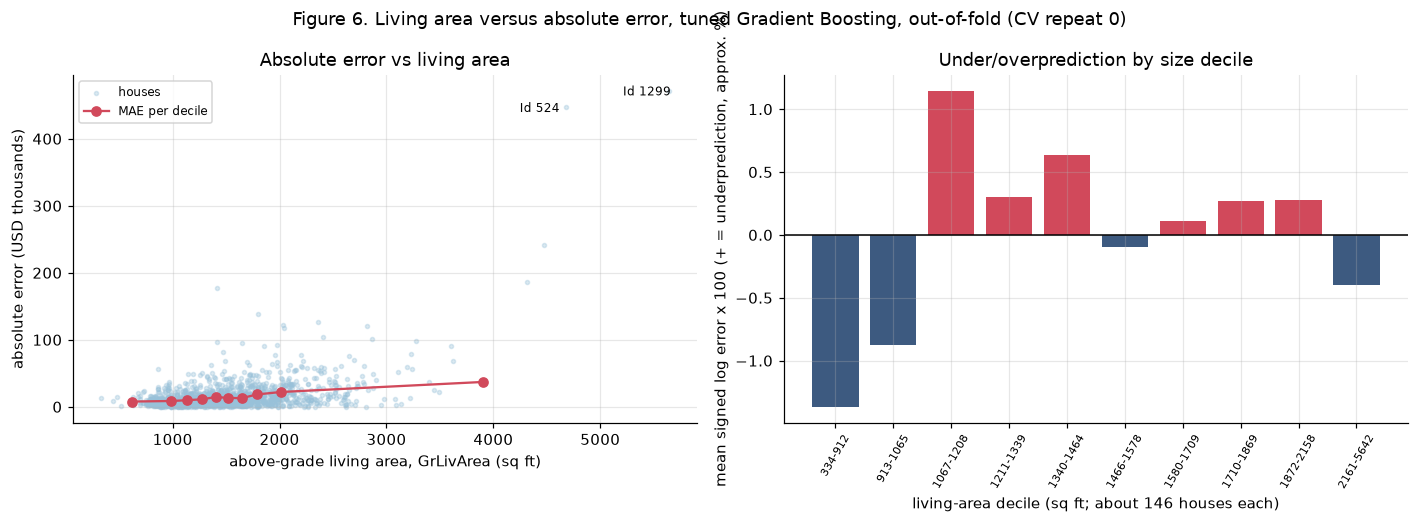

In [14]:
print('Without the two flagged houses (4,676 and 5,642 sq ft):'); display(S.segment_table(Gx, 'gbr_tuned', 'area_group')[COLS].round(FMT))
G0['area_decile'] = pd.qcut(G0.GrLivArea, 10, labels=False, duplicates='drop')
dec = G0.groupby('area_decile').agg(n=('Id', 'size'), area_lo=('GrLivArea', 'min'), area_hi=('GrLivArea', 'max'), mae=('abs_err_usd', 'mean'), mape=('ape', lambda s: 100 * s.mean()), signed_usd=('residual_usd', 'mean'), signed_log=('residual_log', 'mean'), sd_log=('residual_log', 'std'))
print('By living-area decile (houses, repeat 0):'); display(dec.round({'area_lo': 0, 'area_hi': 0, 'mae': 0, 'mape': 2, 'signed_usd': 0, 'signed_log': 3, 'sd_log': 3}))
print('Spearman(living area, |USD error|) = %.3f; Spearman(living area, |log error|) = %.3f; Spearman(living area, signed log error) = %.3f' % (stats.spearmanr(G0.GrLivArea, G0.abs_err_usd)[0], stats.spearmanr(G0.GrLivArea, G0.residual_log.abs())[0], stats.spearmanr(G0.GrLivArea, G0.residual_log)[0]))
print('Same without flagged houses: |USD error| %.3f, signed log error %.3f' % (stats.spearmanr(G0x.GrLivArea, G0x.abs_err_usd)[0], stats.spearmanr(G0x.GrLivArea, G0x.residual_log)[0]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(G0.GrLivArea, G0.abs_err_usd / 1e3, s=7, alpha=.35, color='#98c1d9', label='houses'); axes[0].plot((dec.area_lo + dec.area_hi) / 2, dec.mae / 1e3, 'o-', color='#d1495b', label='MAE per decile')
for i in E.FLAGGED_IDS:
    r = G0[G0.Id == i].iloc[0]; axes[0].annotate(f'Id {i}', (r.GrLivArea, r.abs_err_usd / 1e3), fontsize=8, xytext=(-30, -3), textcoords='offset points')
axes[0].set_xlabel('above-grade living area, GrLivArea (sq ft)'); axes[0].set_ylabel('absolute error (USD thousands)'); axes[0].set_title('Absolute error vs living area'); axes[0].legend(fontsize=8)
axes[1].bar(range(len(dec)), dec.signed_log * 100, color=['#d1495b' if v > 0 else '#3d5a80' for v in dec.signed_log]); axes[1].axhline(0, color='k', lw=1)
axes[1].set_xticks(range(len(dec))); axes[1].set_xticklabels([f'{int(a)}-{int(b)}' for a, b in zip(dec.area_lo, dec.area_hi)], rotation=60, fontsize=7); axes[1].set_xlabel('living-area decile (sq ft; about 146 houses each)'); axes[1].set_ylabel('mean signed log error x 100 (+ = underprediction, approx. %)'); axes[1].set_title('Under/overprediction by size decile')
fig.suptitle('Figure 6. Living area versus absolute error, tuned Gradient Boosting, out-of-fold (CV repeat 0)'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig6_area.png'); plt.show()

In [15]:
tab = S.segment_table(O, 'gbr_tuned', 'YrSold')
tab = S.with_ci(tab, G0, 'YrSold')
cls = S.seg_vs_rest(G0, 'YrSold')
out = tab[COLS + ['log_rmse_lo', 'log_rmse_hi', 'mae_lo', 'mae_hi', 'mape_lo', 'mape_hi', 'signed_usd_lo', 'signed_usd_hi']].join(cls[['logrmse_diff_vs_rest', 'class']])
print('Sale year (metadata only; NOT a predictor)')
display(out.round(dict(FMT, log_rmse_lo=3, log_rmse_hi=3, mae_lo=0, mae_hi=0, mape_lo=2, mape_hi=2, signed_usd_lo=0, signed_usd_hi=0, logrmse_diff_vs_rest=3)))
SEG['YrSold'] = out

Sale year (metadata only; NOT a predictor)


,n,log_rmse,mae,median_ae,rmse_usd,mape,signed_usd,signed_log,sd_log_resid,log_rmse_lo,log_rmse_hi,mae_lo,mae_hi,mape_lo,mape_hi,signed_usd_lo,signed_usd_hi,logrmse_diff_vs_rest,class
YrSold,,,,,,,,,,,,,,,,,,,
2006,314.0,0.111,14645.0,9595.0,22624.0,7.99,3759.0,0.015,0.111,0.096,0.121,12773.0,15981.0,7.14,8.76,1051.0,5596.0,-0.026,practical only
2007,329.0,0.134,17858.0,9825.0,38035.0,8.93,2819.0,0.005,0.134,0.105,0.174,14220.0,21498.0,7.58,11.03,-2505.0,5956.0,0.010,descriptive only
2008,304.0,0.123,14419.0,8971.0,25848.0,8.39,1378.0,0.001,0.123,0.095,0.184,12415.0,19090.0,7.14,11.49,-3513.0,4144.0,0.007,descriptive only
2009,338.0,0.139,15531.0,10372.0,23781.0,9.65,-1256.0,-0.014,0.139,0.118,0.162,13954.0,17652.0,8.51,11.34,-3788.0,1172.0,0.013,descriptive only
2010,175.0,0.118,14712.0,9757.0,22348.0,8.71,1164.0,-0.005,0.118,0.102,0.134,12805.0,17816.0,7.59,10.20,-1676.0,5293.0,-0.013,descriptive only


USD R2 by sale year (mean over repeats): {2006: np.float64(0.918), 2007: np.float64(0.803), 2008: np.float64(0.856), 2009: np.float64(0.913), 2010: np.float64(0.922)}
Median sale price by year: {2006: 163995, 2007: 167000, 2008: 164000, 2009: 162000, 2010: 155000}


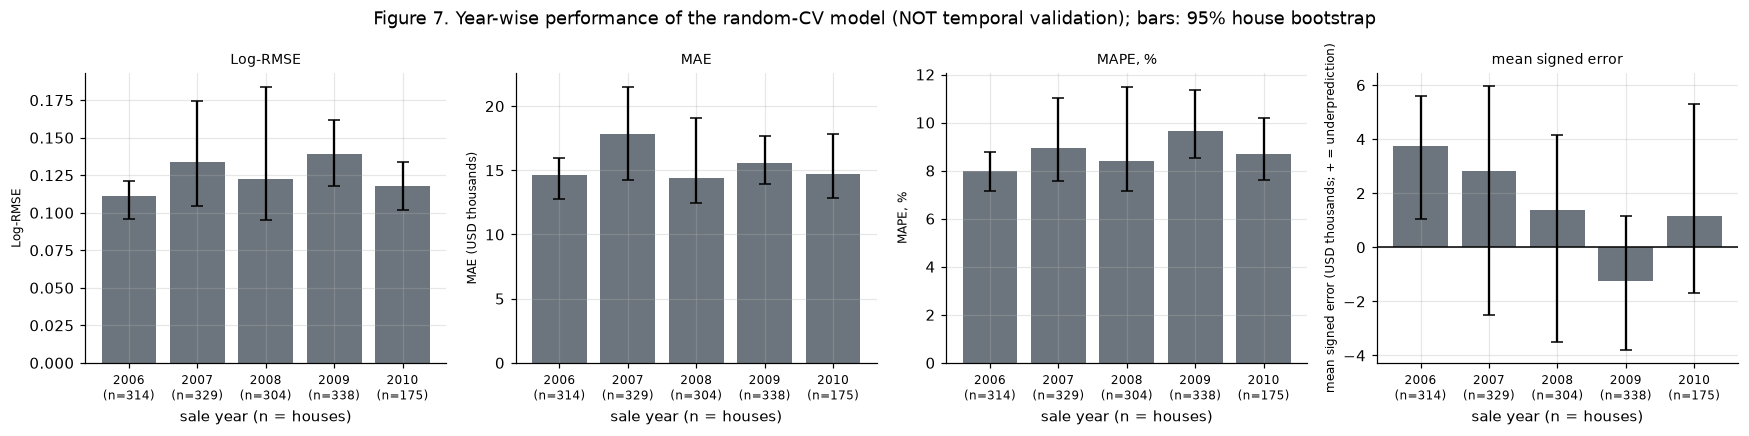

In [16]:
yr = S.segment_table(O, 'gbr_tuned', 'YrSold')
# R2 on the USD scale is reported here because each year has 175-338 houses and covers the whole price range
r2 = {k: np.mean([1 - ((g.y - g.pred) ** 2).sum() / ((g.y - g.y.mean()) ** 2).sum() for _, g in d.groupby('repeat')]) for k, d in G.groupby('YrSold')}
print('USD R2 by sale year (mean over repeats):', {int(k): round(v, 3) for k, v in r2.items()})
print('Median sale price by year:', df.groupby('YrSold').SalePrice.median().astype(int).to_dict())
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
t = SEG['YrSold']; yrs = t.index.astype(int)
for ax, (key, lab, sc_) in zip(axes, [('log_rmse', 'Log-RMSE', 1), ('mae', 'MAE (USD thousands)', 1e3), ('mape', 'MAPE, %', 1), ('signed_usd', 'mean signed error (USD thousands; + = underprediction)', 1e3)]):
    ax.bar(range(len(yrs)), t[key] / sc_, yerr=None if key not in ('mae', 'mape', 'log_rmse', 'signed_usd') else [(t[key] - t[key + '_lo']) / sc_, (t[key + '_hi'] - t[key]) / sc_], color='#6c757d', capsize=4)
    ax.set_xticks(range(len(yrs))); ax.set_xticklabels([f'{y_}\n(n={int(n)})' for y_, n in zip(yrs, t.n)], fontsize=8); ax.set_xlabel('sale year (n = houses)'); ax.set_ylabel(lab, fontsize=8); ax.set_title(lab.split(' (')[0], fontsize=9)
    if key == 'signed_usd': ax.axhline(0, color='k', lw=1)
fig.suptitle('Figure 7. Year-wise performance of the random-CV model (NOT temporal validation); bars: 95% house bootstrap'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig7_year.png'); plt.show()

In [17]:
TM = pd.read_csv(TP.OUT / 'temporal_metrics.csv'); RM = pd.read_csv(TP.OUT / 'random_matched_splits.csv'); HT = json.loads((TP.OUT / 'historical_tuning.json').read_text())
print('Historical-only tuned parameters (selected from the 947 training houses):'); display(pd.DataFrame({f: v['params'] for f, v in HT.items()}).T)
FM = E.fold_metrics(E.load_oof(), ()); FMx = E.fold_metrics(E.load_oof(), E.FLAGGED_IDS)
FAM = {'gbr': ('gbr_tuned', 'Gradient Boosting'), 'elasticnet': ('enet_tuned', 'ElasticNet')}
rows = []
for fam, (mid, lab) in FAM.items():
    for nm, fm in [('Random 5-fold CV, nested-tuned (development; all houses)', FM), ('Random 5-fold CV, nested-tuned, without Ids 524/1299', FMx)]:
        s = fm[fm.model == mid]
        rows.append({'Model': lab, 'Evaluation Protocol': nm, 'Training Period': '2006-2010 (random 80%)', 'Evaluation Period': '2006-2010 (random 20%)', 'N Train': 1168, 'N Test': 292, 'Log-RMSE': s.rmse_log.mean(), 'MAE USD': s.mae.mean(), 'RMSE USD': s.rmse_usd.mean(), 'MAPE %': s.mape.mean(), 'R2 USD': s.r2_usd.mean(), 'Mean signed USD': np.nan})
    r = RM[RM.family == fam]
    rows.append({'Model': lab, 'Evaluation Protocol': 'Random matched-size split, fixed config (mean of 30; all test houses)', 'Training Period': '2006-2010 (random 947)', 'Evaluation Period': '2006-2010 (random 513)', 'N Train': 947, 'N Test': 513, 'Log-RMSE': r.log_rmse.mean(), 'MAE USD': r.mae.mean(), 'RMSE USD': r.rmse_usd.mean(), 'MAPE %': r.mape.mean(), 'R2 USD': r.r2_usd.mean(), 'Mean signed USD': r.signed_usd.mean()})
    rows.append({'Model': lab, 'Evaluation Protocol': 'Random matched-size split, fixed config (mean of 30; test without 524/1299)', 'Training Period': '2006-2010 (random 947)', 'Evaluation Period': '2006-2010 (random 513)', 'N Train': 947, 'N Test': 513 - r.flagged_in_test.mean(), 'Log-RMSE': r.log_rmse_noflag.mean(), 'MAE USD': r.mae_noflag.mean(), 'RMSE USD': r.rmse_usd_noflag.mean(), 'MAPE %': r.mape_noflag.mean(), 'R2 USD': r.r2_usd_noflag.mean(), 'Mean signed USD': r.signed_usd_noflag.mean()})
    for cfg, nm in [('fixed', 'Temporal holdout, fixed config (no tuning)'), ('hist_tuned', 'Temporal holdout, historical-only tuned (clean)'), ('all_years_tuned', 'Temporal holdout, all-years-tuned (EXPLORATORY, optimistic)')]:
        t = TM[(TM.family == fam) & (TM.config == cfg) & (TM.period == '2009-2010')].iloc[0]
        rows.append({'Model': lab, 'Evaluation Protocol': nm, 'Training Period': '2006-2008', 'Evaluation Period': '2009-2010', 'N Train': 947, 'N Test': 513, 'Log-RMSE': t.log_rmse, 'MAE USD': t.mae, 'RMSE USD': t.rmse_usd, 'MAPE %': t.mape, 'R2 USD': t.r2_usd, 'Mean signed USD': t.signed_usd})
TT = pd.DataFrame(rows).set_index(['Model', 'Evaluation Protocol'])
display(TT.round({'N Test': 0, 'Log-RMSE': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3, 'Mean signed USD': 0}))
TT.round(4).to_csv(TAB / 'segments_temporal_comparison.csv')
print('Matched-size random splits: Log-RMSE distribution (30 splits, 947 train / 513 test):'); display(RM.groupby('family')[['log_rmse', 'log_rmse_noflag']].describe().round(4).T)
rows = []
for fam in FAM:
    r = RM[RM.family == fam]; tf = TM[(TM.family == fam) & (TM.config == 'fixed') & (TM.period == '2009-2010')].log_rmse.iloc[0]
    rows.append({'family': fam, 'temporal fixed Log-RMSE': tf, 'random mean (all test)': r.log_rmse.mean(), 'z (SDs above random mean)': (tf - r.log_rmse.mean()) / r.log_rmse.std(), 'share of random splits as bad or worse': (r.log_rmse >= tf).mean(),
                 'random mean (no 524/1299)': r.log_rmse_noflag.mean(), 'z (no flagged)': (tf - r.log_rmse_noflag.mean()) / r.log_rmse_noflag.std(), 'share as bad or worse (no flagged)': (r.log_rmse_noflag >= tf).mean()})
print('Where the temporal holdout (fixed config, same configuration as the random splits) falls among 30 random splits of the same sizes (descriptive, not a p-value):'); display(pd.DataFrame(rows).set_index('family').round(3))
tpr = pd.read_csv(TP.OUT / 'temporal_predictions.csv.gz'); tg_ = tpr[(tpr.family == 'gbr') & (tpr.config == 'hist_tuned')].copy()
tg_ = E.add_errors(tg_[['row', 'y', 'pred_log']].assign(model='gbr_hist', fold=0)); tg_ = S.add_segments(tg_, df)
tg_['price_pred'] = pd.cut(tg_.pred, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
print('Temporal holdout (historical-only tuned GBR): errors by predicted-price band and quality tier (one prediction per house; small groups)')
display(pd.concat({'price_pred': tg_.groupby('price_pred', observed=True).apply(S.seg_stats, include_groups=False), 'quality_tier': tg_.groupby('quality_tier', observed=True).apply(S.seg_stats, include_groups=False)})[['n', 'log_rmse', 'mae', 'mape', 'signed_usd', 'signed_log']].round({'n': 0, 'log_rmse': 3, 'mae': 0, 'mape': 2, 'signed_usd': 0, 'signed_log': 3}))
print('Temporal holdout by test year (historical-only tuned):'); display(TM[(TM.config == 'hist_tuned') & (TM.period != '2009-2010')][['family', 'period', 'n', 'log_rmse', 'mae', 'rmse_usd', 'mape', 'r2_usd', 'signed_usd', 'signed_log']].round(4).set_index(['family', 'period']))

Historical-only tuned parameters (selected from the 947 training houses):


,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf,alpha,l1_ratio
gbr,450.0,0.05115,3.0,0.686357,3.0,NaN,NaN
elasticnet,NaN,NaN,NaN,NaN,NaN,0.001015,0.4384


Training Period       Evaluation Period  N Train  N Test  Log-RMSE  MAE USD  RMSE USD  MAPE %  R2 USD  Mean signed USD
Model             Evaluation Protocol                                                                                                                                                                                  
Gradient Boosting Random 5-fold CV, nested-tuned (development; all houses)                2006-2010 (random 80%)  2006-2010 (random 20%)     1168   292.0    0.1260  15535.0   26774.0    8.76   0.884              NaN
                  Random 5-fold CV, nested-tuned, without Ids 524/1299                    2006-2010 (random 80%)  2006-2010 (random 20%)     1168   292.0    0.1210  15158.0   24708.0    8.54   0.902              NaN
                  Random matched-size split, fixed config (mean of 30; all test houses)   2006-2010 (random 947)  2006-2010 (random 513)      947   513.0    0.1273  16185.0   28078.0    9.00   0.875           2115.0
                  Random matched-size split, fixed config (mean of 30; test without 5...  2006-2010 (random 947)  2006-2010 (random 513)      947   513.0    0.1251  16009.0   27177.0    8.90   0.883           2308.0
                  Temporal holdout, fixed config (no tuning)                                           2006-2008               2009-2010      947   513.0    0.1365  16666.0   25752.0   10.07   0.898           -557.0
                  Temporal holdout, historical-only tuned (clean)                                      2006-2008               2009-2010      947   513.0    0.1317  16157.0   25315.0    9.67   0.901          -1820.0
                  Temporal holdout, all-years-tuned (EXPLORATORY, optimistic)                          2006-2008               2009-2010      947   513.0    0.1338  16406.0   25887.0    9.78   0.897          -2138.0
ElasticNet        Random 5-fold CV, nested-tuned (development; all houses)                2006-2010 (random 80%)  2006-2010 (random 20%)     1168   292.0    0.1307  16125.0   32014.0    9.06   0.822              NaN
                  Random 5-fold CV, nested-tuned, without Ids 524/1299                    2006-2010 (random 80%)  2006-2010 (random 20%)     1168   292.0    0.1190  15299.0   24704.0    8.57   0.902              NaN
                  Random matched-size split, fixed config (mean of 30; all test houses)   2006-2010 (random 947)  2006-2010 (random 513)      947   513.0    0.1260  15765.0   30819.0    8.74   0.843           1836.0
                  Random matched-size split, fixed config (mean of 30; test without 5...  2006-2010 (random 947)  2006-2010 (random 513)      947   513.0    0.1183  15260.0   25724.0    8.43   0.895           2357.0
                  Temporal holdout, fixed config (no tuning)                                           2006-2008               2009-2010      947   513.0    0.1315  15770.0   25367.0    9.42   0.901            164.0
                  Temporal holdout, historical-only tuned (clean)                                      2006-2008               2009-2010      947   513.0    0.1316  15773.0   25399.0    9.42   0.901            172.0
                  Temporal holdout, all-years-tuned (EXPLORATORY, optimistic)                          2006-2008               2009-2010      947   513.0    0.1315  15887.0   25414.0    9.48   0.901            274.0

Matched-size random splits: Log-RMSE distribution (30 splits, 947 train / 513 test):


family                 elasticnet      gbr
log_rmse        count     30.0000  30.0000
                mean       0.1260   0.1273
                std        0.0121   0.0087
                min        0.1038   0.1097
                25%        0.1164   0.1196
                50%        0.1272   0.1287
                75%        0.1346   0.1330
                max        0.1544   0.1483
log_rmse_noflag count     30.0000  30.0000
                mean       0.1183   0.1251
                std        0.0072   0.0077
                min        0.1038   0.1097
                25%        0.1158   0.1184
                50%        0.1187   0.1259
                75%        0.1215   0.1297
                max        0.1345   0.1483

...

,temporal fixed Log-RMSE,random mean (all test),z (SDs above random mean),share of random splits as bad or worse,random mean (no 524/1299),z (no flagged),share as bad or worse (no flagged)
family,,,,,,,
gbr,0.136,0.127,1.053,0.100,0.125,1.480,0.033
elasticnet,0.131,0.126,0.455,0.333,0.118,1.828,0.067


Temporal holdout (historical-only tuned GBR): errors by predicted-price band and quality tier (one prediction per house; small groups)


n  log_rmse      mae   mape  signed_usd  signed_log
price_pred   low           129.0     0.165  11570.0  12.55      -449.0      -0.018
             mid           330.0     0.114  13979.0   8.33     -2953.0      -0.021
             luxury         54.0     0.143  40428.0  11.03      1831.0      -0.010
quality_tier low (1-4)      62.0     0.171  11581.0  13.53     -2843.0      -0.035
             medium (5-8)  426.0     0.124  15214.0   9.08     -2532.0      -0.019
             high (9-10)    25.0     0.146  43588.0  10.24     12854.0       0.016

Temporal holdout by test year (historical-only tuned):


n  log_rmse         mae    rmse_usd     mape  r2_usd  signed_usd  signed_log
family     period                                                                                
gbr        2009    338    0.1380  16484.5973  25106.3200  10.0519  0.9034  -2438.8549     -0.0219
           2010    175    0.1186  15525.1046  25713.5153   8.9420  0.8973   -624.0492     -0.0130
elasticnet 2009    338    0.1386  16035.9937  25181.8186   9.7620  0.9028   -352.3823     -0.0142
           2010    175    0.1169  15263.7736  25814.3385   8.7655  0.8965   1184.9467     -0.0064

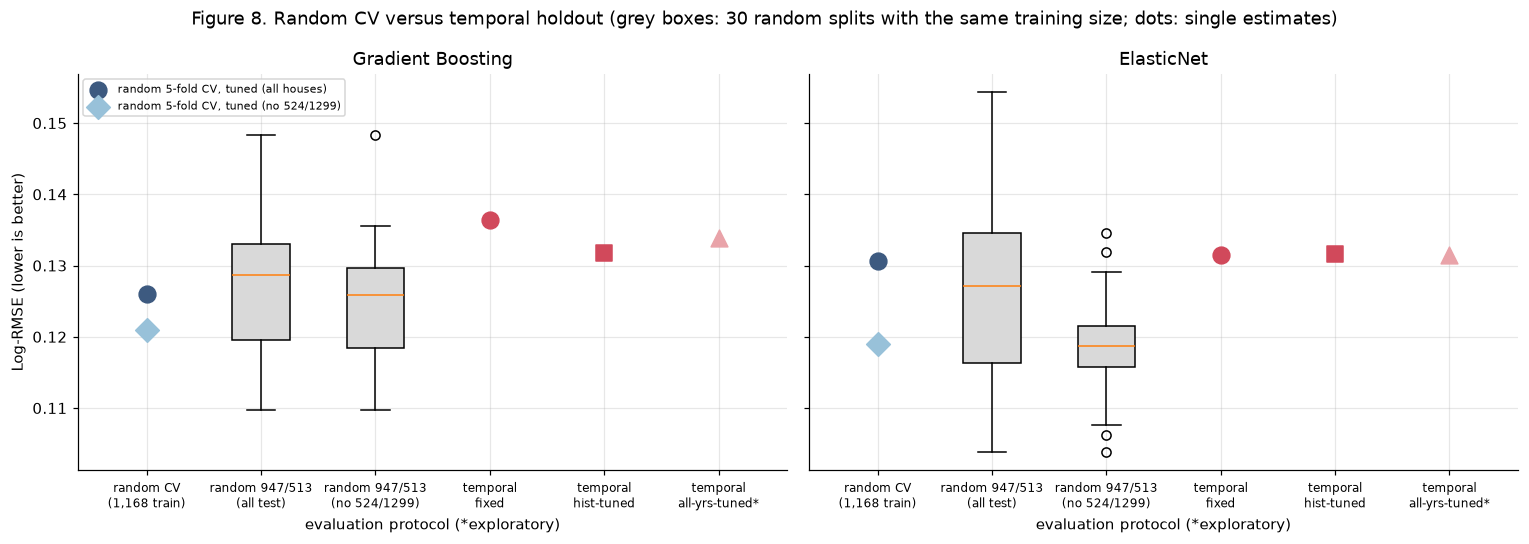

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (fam, (mid, lab)) in zip(axes, FAM.items()):
    r = RM[RM.family == fam]
    bp = ax.boxplot([r.log_rmse, r.log_rmse_noflag], positions=[2, 3], widths=.5, patch_artist=True, showfliers=True)
    for b_ in bp['boxes']: b_.set_facecolor('#d9d9d9')
    ax.scatter([1], [FM[FM.model == mid].rmse_log.mean()], s=120, color='#3d5a80', zorder=3, label='random 5-fold CV, tuned (all houses)'); ax.scatter([1.0], [FMx[FMx.model == mid].rmse_log.mean()], s=120, marker='D', color='#98c1d9', zorder=3, label='random 5-fold CV, tuned (no 524/1299)')
    for xpos, cfg, mk, col in [(4, 'fixed', 'o', '#d1495b'), (5, 'hist_tuned', 's', '#d1495b'), (6, 'all_years_tuned', '^', '#e9a3a9')]:
        v = TM[(TM.family == fam) & (TM.config == cfg) & (TM.period == '2009-2010')].log_rmse.iloc[0]; ax.scatter([xpos], [v], s=120, marker=mk, color=col, zorder=3)
    ax.set_xticks([1, 2, 3, 4, 5, 6]); ax.set_xticklabels(['random CV\n(1,168 train)', 'random 947/513\n(all test)', 'random 947/513\n(no 524/1299)', 'temporal\nfixed', 'temporal\nhist-tuned', 'temporal\nall-yrs-tuned*'], fontsize=8)
    ax.set_xlabel('evaluation protocol (*exploratory)'); ax.set_title(lab); ax.set_xlim(.4, 6.6)
axes[0].set_ylabel('Log-RMSE (lower is better)'); axes[0].legend(fontsize=7, loc='upper left')
fig.suptitle('Figure 8. Random CV versus temporal holdout (grey boxes: 30 random splits with the same training size; dots: single estimates)'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig8_random_vs_temporal.png'); plt.show()

In [19]:
tr_i, te_i = TP.split_indices(df)
raw = df.copy()
raw['TotalSF'] = raw.TotalBsmtSF + raw['1stFlrSF'] + raw['2ndFlrSF']; raw['HouseAge'] = 2010 - raw.YearBuilt
raw['TotalBathrooms'] = raw.FullBath + .5 * raw.HalfBath + raw.BsmtFullBath + .5 * raw.BsmtHalfBath
feats = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'HouseAge', 'LotArea', 'TotalSF', 'TotalBathrooms', 'OverallCond']
rows = []
for f in feats:
    a, b = raw[f].iloc[tr_i].astype(float), raw[f].iloc[te_i].astype(float)
    sd = np.sqrt((a.var() + b.var()) / 2); ks = stats.ks_2samp(a, b)
    rows.append({'feature': f, 'train mean': a.mean(), 'test mean': b.mean(), 'SMD': (b.mean() - a.mean()) / sd, 'KS stat': ks.statistic, 'KS p (rough)': ks.pvalue, 'train median': a.median(), 'test median': b.median()})
SH = pd.DataFrame(rows).set_index('feature'); display(SH.round(3)); SH.round(4).to_csv(TAB / 'segments_distribution_shift.csv')
ns = pd.DataFrame({'train share': raw.Neighborhood.iloc[tr_i].value_counts(normalize=True), 'test share': raw.Neighborhood.iloc[te_i].value_counts(normalize=True)}).fillna(0)
ns['difference (pp)'] = 100 * (ns['test share'] - ns['train share']); tv = 0.5 * (ns['test share'] - ns['train share']).abs().sum()
chi = stats.chi2_contingency(pd.crosstab(raw.Neighborhood, raw.YrSold > 2008).values)
print(f'Neighbourhood mix: total-variation distance {tv:.3f}; chi-square p = {chi.pvalue:.3f} (rough). Largest share changes (percentage points):'); display(ns.sort_values('difference (pp)').iloc[[0, 1, 2, -3, -2, -1]].round(3))
print('Target (retrospective diagnostic only): median price train %d, test %d; mean %.0f / %.0f; share of luxury (>= $280k) %.1f%% / %.1f%%' % (raw.SalePrice.iloc[tr_i].median(), raw.SalePrice.iloc[te_i].median(), raw.SalePrice.iloc[tr_i].mean(), raw.SalePrice.iloc[te_i].mean(), 100 * (raw.SalePrice.iloc[tr_i] >= 280000).mean(), 100 * (raw.SalePrice.iloc[te_i] >= 280000).mean()))
print('Share of test houses built after 2008 (structurally absent from the training years):', round(float((raw.YearBuilt.iloc[te_i] > 2008).mean()), 3), '| built after 2005:', round(float((raw.YearBuilt.iloc[te_i] > 2005).mean()), 3), 'vs train', round(float((raw.YearBuilt.iloc[tr_i] > 2005).mean()), 3))

,train mean,test mean,SMD,KS stat,KS p (rough),train median,test median
feature,,,,,,,
OverallQual,6.126,6.051,-0.054,0.037,0.721,6.0,6.0
GrLivArea,1526.413,1495.251,-0.061,0.036,0.759,1456.0,1473.0
TotalBsmtSF,1061.105,1050.645,-0.024,0.039,0.674,992.0,991.0
GarageCars,1.772,1.758,-0.018,0.022,0.995,2.0,2.0
YearBuilt,1971.144,1971.497,0.012,0.061,0.162,1972.0,1973.0
HouseAge,38.856,38.503,-0.012,0.061,0.162,38.0,37.0
LotArea,10651.003,10269.140,-0.038,0.043,0.564,9503.0,9375.0
TotalSF,2581.175,2540.971,-0.050,0.034,0.828,2490.0,2448.0
TotalBathrooms,2.201,2.228,0.034,0.025,0.981,2.0,2.0


Neighbourhood mix: total-variation distance 0.077; chi-square p = 0.520 (rough). Largest share changes (percentage points):


,train share,test share,difference (pp)
Neighborhood,,,
Crawfor,0.041,0.023,-1.779
Somerst,0.063,0.051,-1.268
Veenker,0.012,0.000,-1.162
Edwards,0.065,0.074,0.860
NridgHt,0.050,0.058,0.885
SawyerW,0.033,0.055,2.185


Target (retrospective diagnostic only): median price train 164990, test 160000; mean 182105 / 178737; share of luxury (>= $280k) 10.2% / 9.2%
Share of test houses built after 2008 (structurally absent from the training years): 0.037 | built after 2005: 0.111 vs train 0.107


In [20]:
# Domain classifier: can a model tell test-period houses from training-period houses using predictors only (no sale-date columns)?
lab_ = (df.YrSold.values > 2008).astype(int)
def domain_auc(drop_extra):
    pre = P.build_preprocessor('baseline', scale=None, drop_columns=list(REDUCED_DROP) + list(drop_extra))
    pipe = Pipeline([('prep', pre), ('clf', HistGradientBoostingClassifier(max_depth=3, learning_rate=.1, max_iter=150, random_state=42))])
    aucs = []
    for seed in range(5):
        p = cross_val_predict(pipe, X, lab_, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
        aucs.append(roc_auc_score(lab_, p))
    return np.mean(aucs), np.std(aucs)
a1 = domain_auc([]); a2 = domain_auc(['HouseAge', 'RemodAge'])
print('Domain-classifier AUC (0.5 = indistinguishable; mean/SD over 5 CV shuffles):'); display(pd.DataFrame({'AUC': [a1[0], a2[0]], 'SD': [a1[1], a2[1]]}, index=['all predictors', 'without HouseAge and RemodAge']).round(3))
# novelty: distance of each test house to its 5 nearest training houses, relative to training-to-training distances
nf = ['OverallQual', 'GrLivArea', 'YearBuilt', 'TotalBsmtSF', 'GarageCars', 'LotArea']
Z = raw[nf].astype(float).copy(); Z['GrLivArea'] = np.log1p(Z.GrLivArea); Z['TotalBsmtSF'] = np.log1p(Z.TotalBsmtSF); Z['LotArea'] = np.log1p(Z.LotArea)
mu, sdv = Z.iloc[tr_i].mean(), Z.iloc[tr_i].std(); Zs = ((Z - mu) / sdv).values
nn = NearestNeighbors(n_neighbors=6).fit(Zs[tr_i]); dtr = nn.kneighbors(Zs[tr_i])[0][:, 1:].mean(1); dte = nn.kneighbors(Zs[te_i])[0][:, :5].mean(1)
thr = np.percentile(dtr, 95)
print(f'Novelty (mean distance to 5 nearest training houses): training houses median {np.median(dtr):.2f}; test houses median {np.median(dte):.2f}; share of test houses beyond the training 95th percentile ({thr:.2f}): {np.mean(dte > thr):.3f} (5% expected without shift)')
tp = pd.read_csv(TP.OUT / 'temporal_predictions.csv.gz'); tg = tp[(tp.family == 'gbr') & (tp.config == 'hist_tuned')].reset_index(drop=True)
abs_log = np.abs(np.log1p(tg.y) - tg.pred_log); order_te = pd.Series(te_i).values
assert (tg.row.values == te_i).all()
print('Spearman(novelty, |log error|) in the temporal test set = %.3f' % stats.spearmanr(dte, abs_log)[0], '| mean |log error| for novel (beyond P95) vs other test houses: %.3f vs %.3f' % (abs_log[dte > thr].mean(), abs_log[dte <= thr].mean()), '| n novel =', int((dte > thr).sum()))

Domain-classifier AUC (0.5 = indistinguishable; mean/SD over 5 CV shuffles):


,AUC,SD
all predictors,0.554,0.011
without HouseAge and RemodAge,0.507,0.015


Novelty (mean distance to 5 nearest training houses): training houses median 0.49; test houses median 0.50; share of test houses beyond the training 95th percentile (1.46): 0.049 (5% expected without shift)
Spearman(novelty, |log error|) in the temporal test set = 0.226 | mean |log error| for novel (beyond P95) vs other test houses: 0.130 vs 0.090 | n novel = 25


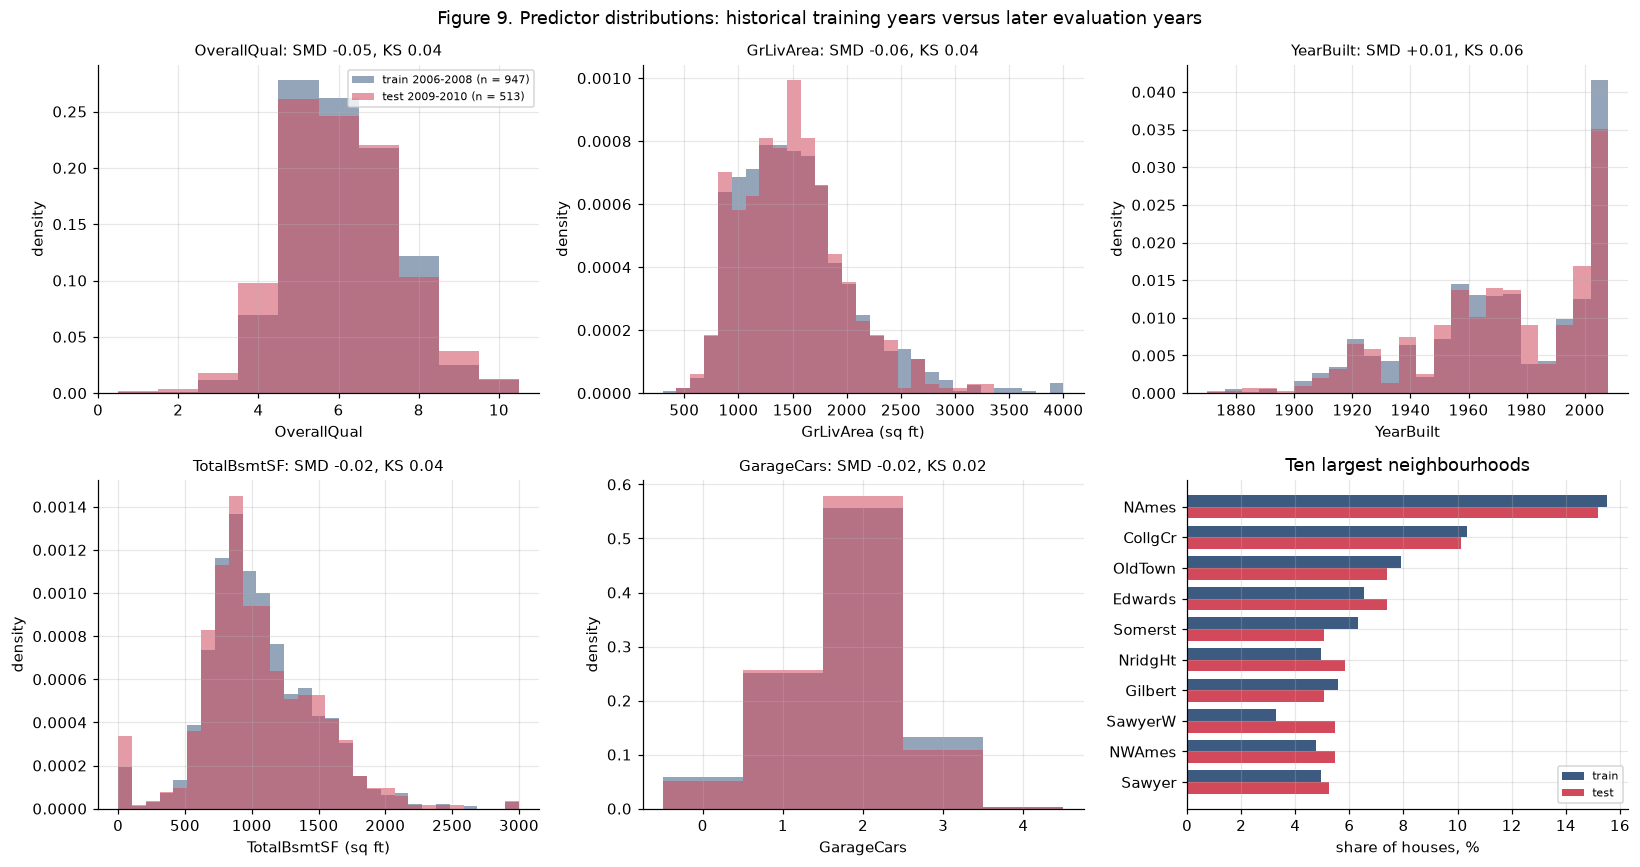

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f, bins in zip(axes.ravel()[:5], ['OverallQual', 'GrLivArea', 'YearBuilt', 'TotalBsmtSF', 'GarageCars'], [np.arange(.5, 11, 1), np.linspace(300, 4000, 30), np.arange(1870, 2012, 6), np.linspace(0, 3000, 30), np.arange(-.5, 5, 1)]):
    ax.hist(raw[f].iloc[tr_i].clip(bins[0], bins[-1]), bins=bins, density=True, alpha=.55, color='#3d5a80', label=f'train 2006-2008 (n = {len(tr_i)})')
    ax.hist(raw[f].iloc[te_i].clip(bins[0], bins[-1]), bins=bins, density=True, alpha=.55, color='#d1495b', label=f'test 2009-2010 (n = {len(te_i)})')
    ax.set_xlabel(f + (' (sq ft)' if f in ('GrLivArea', 'TotalBsmtSF') else '')); ax.set_ylabel('density'); ax.set_title(f'{f}: SMD {SH.loc[f, "SMD"]:+.2f}, KS {SH.loc[f, "KS stat"]:.2f}', fontsize=10)
axes[0, 0].legend(fontsize=7)
top = ns.reindex(ns[['train share', 'test share']].max(axis=1).sort_values(ascending=False).index[:10])
w = .38; axes[1, 2].barh(np.arange(len(top)) - w / 2, 100 * top['train share'], w, color='#3d5a80', label='train'); axes[1, 2].barh(np.arange(len(top)) + w / 2, 100 * top['test share'], w, color='#d1495b', label='test')
axes[1, 2].set_yticks(range(len(top))); axes[1, 2].set_yticklabels(top.index); axes[1, 2].invert_yaxis(); axes[1, 2].set_xlabel('share of houses, %'); axes[1, 2].set_title('Ten largest neighbourhoods'); axes[1, 2].legend(fontsize=7)
fig.suptitle('Figure 9. Predictor distributions: historical training years versus later evaluation years'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig9_shift.png'); plt.show()

In [22]:
IVS = {}
for lab, by in [('price (predicted)', 'price_pred'), ('price (actual, retrospective)', 'price_actual'), ('quality tier', 'quality_tier'), ('age group', 'age_group'), ('living area', 'area_group'), ('sale year', 'YrSold')]:
    t = S.interval_segment_table(O, by); t.index = [f'{lab}: {i}' for i in t.index]; IVS[by] = t
nbi = S.interval_segment_table(O, 'Neighborhood'); nbi = nbi[nbi.n >= S.MIN_N_NEIGHBORHOOD]; nbi.index = [f'neighbourhood: {i}' for i in nbi.index]
IV = pd.concat(list(IVS.values()) + [nbi])
overall = G.groupby('repeat').agg(c=('cover_cqr', 'mean'), w=('width_cqr', 'mean'), r=('relwidth_cqr', 'median')).mean()
print('Overall CQR coverage %.3f, mean width $%.0f, median relative width %.1f%%' % (overall.c, overall.w, 100 * overall.r))
display(IV[['n', 'coverage', 'cov_ci_lo', 'cov_ci_hi', 'gap_pp', 'mean_width_usd', 'median_rel_width_pct']].round({'n': 0, 'coverage': 3, 'cov_ci_lo': 3, 'cov_ci_hi': 3, 'gap_pp': 1, 'mean_width_usd': 0, 'median_rel_width_pct': 1}))
IV.round(4).to_csv(TAB / 'segments_interval_coverage.csv')
hist_rows = []
for lab, mk in [('Luxury (predicted price)', G.price_pred == 'luxury'), ('Crawfor', G.Neighborhood == 'Crawfor'), ('StoneBr (n = 25, small)', G.Neighborhood == 'StoneBr'), ('Sold in 2010', G.YrSold == 2010)]:
    g = G[mk]; r0 = g[g.repeat == 0]; lo, hi = V.wilson(int(r0.cover_cqr.sum()), len(r0))
    hist_rows.append({'group': lab, 'n': len(r0), 'CQR coverage': g.groupby('repeat').cover_cqr.mean().mean(), '95% CI': f'{lo:.2f} to {hi:.2f}', 'p (< 80%, one-sided binomial)': stats.binomtest(int(r0.cover_cqr.sum()), len(r0), .8, alternative='less').pvalue})
print('Groups flagged in earlier discussion, re-examined here (same intervals as 07):'); display(pd.DataFrame(hist_rows).set_index('group').round(3))
tcq = pd.read_csv(V.OUT / 'temporal_intervals.csv.gz')
print('Temporal CQR (07: calibrated on 2006-2008 only; 20 random calibration splits): coverage by test year'); display(pd.DataFrame({'CQR coverage': [tcq[tcq.YrSold == yv].groupby('seed').cover_cqr.mean().mean() for yv in (2009, 2010)] , 'min over splits': [tcq[tcq.YrSold == yv].groupby('seed').cover_cqr.mean().min() for yv in (2009, 2010)], 'max over splits': [tcq[tcq.YrSold == yv].groupby('seed').cover_cqr.mean().max() for yv in (2009, 2010)]}, index=[2009, 2010]).round(3))

Overall CQR coverage 0.807, mean width $56702, median relative width 27.0%


,n,coverage,cov_ci_lo,cov_ci_hi,gap_pp,mean_width_usd,median_rel_width_pct
price (predicted): low,371.0,0.809,0.778,0.856,0.9,41857.0,36.1
price (predicted): mid,947.0,0.810,0.764,0.816,1.0,47546.0,23.5
price (predicted): luxury,142.0,0.784,0.693,0.832,-1.6,156592.0,43.3
"price (actual, retrospective): low",365.0,0.755,0.707,0.795,-4.5,41507.0,35.2
"price (actual, retrospective): mid",951.0,0.840,0.804,0.852,4.0,48738.0,23.8
"price (actual, retrospective): luxury",144.0,0.720,0.608,0.758,-8.0,147817.0,42.7
quality tier: low (1-4),141.0,0.794,0.751,0.877,-0.6,49745.0,48.0
quality tier: medium (5-8),1258.0,0.809,0.771,0.816,0.9,50710.0,25.3
quality tier: high (9-10),61.0,0.792,0.669,0.871,-0.8,196371.0,49.8
age group: <=10 yr,388.0,0.817,0.748,0.829,1.7,76224.0,25.2


Groups flagged in earlier discussion, re-examined here (same intervals as 03e):


,n,CQR coverage,95% CI,"p (< 80%, one-sided binomial)"
group,,,,
Luxury (predicted price),139,0.784,0.69 to 0.83,0.214
Crawfor,51,0.693,0.57 to 0.81,0.071
"StoneBr (n = 25, small)",25,0.707,0.48 to 0.83,0.109
Sold in 2010,175,0.779,0.70 to 0.83,0.196


Temporal CQR (03e: calibrated on 2006-2008 only; 20 random calibration splits): coverage by test year


,CQR coverage,min over splits,max over splits
2009,0.770,0.731,0.811
2010,0.761,0.726,0.811


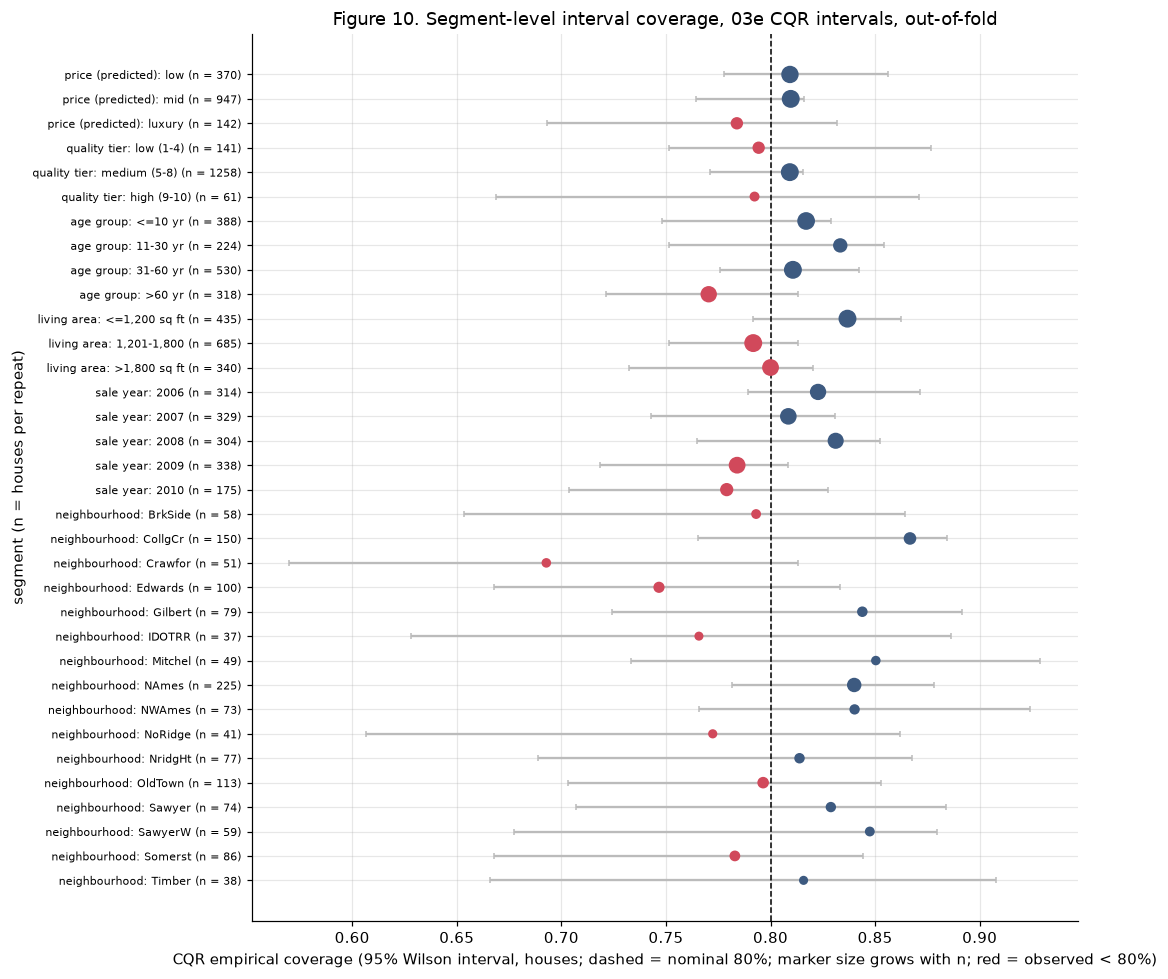

In [23]:
fig, ax = plt.subplots(figsize=(10, 9))
sel = IV.copy(); sel = sel[~sel.index.str.startswith('price (actual')]
sel = sel.iloc[::-1]
colr = ['#d1495b' if c < .8 else '#3d5a80' for c in sel.coverage]
ax.errorbar(sel.coverage, range(len(sel)), xerr=[sel.coverage - sel.cov_ci_lo, sel.cov_ci_hi - sel.coverage], fmt='none', ecolor='#bbbbbb', capsize=2)
ax.scatter(sel.coverage, range(len(sel)), c=colr, s=np.clip(sel.n, 20, 400) / 4 + 15, zorder=3)
ax.axvline(.8, color='k', ls='--', lw=1); ax.set_yticks(range(len(sel))); ax.set_yticklabels([f'{i} (n = {int(n)})' for i, n in zip(sel.index, sel.n)], fontsize=7)
ax.set_xlabel('CQR empirical coverage (95% Wilson interval, houses; dashed = nominal 80%; marker size grows with n; red = observed < 80%)'); ax.set_ylabel('segment (n = houses per repeat)')
ax.set_title('Figure 10. Segment-level interval coverage, 07 CQR intervals, out-of-fold'); plt.tight_layout(); plt.savefig(FIG / 'segments_fig10_interval_coverage.png'); plt.show()

In [24]:
parts = []
for typ, by in [('Price (predicted, deployable)', 'price_pred'), ('Price (actual, retrospective)', 'price_actual'), ('Quality (OverallQual)', 'quality_tier'), ('Property age', 'age_group'), ('Living area', 'area_group'), ('Sale year (metadata)', 'YrSold')]:
    t = SEG[by]; t = t.copy(); t.index = [str(i) for i in t.index]
    parts.append(pd.DataFrame({'Segment Type': typ, 'Group': t.index, 'N': t.n.values, 'Log-RMSE': t.log_rmse.values, 'MAE USD': t.mae.values, 'RMSE USD': t.rmse_usd.values, 'MAPE %': t.mape.values, 'Mean Signed Error USD': t.signed_usd.values, 'Median AE USD': t.median_ae.values, 'Evidence class (Log-RMSE vs rest)': t['class'].values}))
nbd = nbt[nbt['detailed (n>=30)']]
parts.append(pd.DataFrame({'Segment Type': 'Neighbourhood (n >= 30)', 'Group': nbd.index, 'N': nbd.n.values, 'Log-RMSE': nbd.log_rmse.values, 'MAE USD': nbd.mae.values, 'RMSE USD': nbd.rmse_usd.values, 'MAPE %': nbd.mape.values, 'Mean Signed Error USD': nbd.signed_usd.values, 'Median AE USD': nbd.median_ae.values, 'Evidence class (Log-RMSE vs rest)': d.reindex(nbd.index)['class'].values}))
CONS = pd.concat(parts, ignore_index=True)
display(CONS.round({'N': 0, 'Log-RMSE': 3, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'Mean Signed Error USD': 0, 'Median AE USD': 0}).set_index(['Segment Type', 'Group']))
CONS.round(4).to_csv(TAB / 'segments_consolidated.csv', index=False)
ov = {k: np.mean([S.seg_stats(G[G.repeat == r])[k] for r in range(3)]) for k in ['log_rmse', 'mae', 'rmse_usd', 'mape', 'signed_usd']}
print('Overall (all houses): Log-RMSE %.3f, MAE $%.0f, RMSE $%.0f, MAPE %.2f%%, mean signed error $%.0f' % tuple(ov.values()))
print('The temporal comparison table is in section 9 (saved as reports/tables/segments_temporal_comparison.csv); the interval table is in section 11 (segments_interval_coverage.csv).')

N  Log-RMSE  MAE USD  RMSE USD  MAPE %  Mean Signed Error USD  Median AE USD Evidence class (Log-RMSE vs rest)
Segment Type                  Group                                                                                                                             
Price (predicted, deployable) low             371.0     0.150  10280.0   14076.0   10.63                  972.0         7530.0                    practical only
                              mid             947.0     0.103  13563.0   19847.0    7.38                 1289.0         9471.0             supported + practical
                              luxury          142.0     0.189  42402.0   69202.0   13.06                 5045.0        27374.0                    practical only
Price (actual, retrospective) low             365.0     0.159  10928.0   15642.0   11.75                -4595.0         7639.0             supported + practical
                              mid             951.0     0.108  13805.0   23662.0    7.43                  538.0         9233.0             supported + practical
                              luxury          144.0     0.145  38638.0   58462.0    9.94                24104.0        26887.0                    practical only
Quality (OverallQual)         low (1-4)       141.0     0.185  12275.0   16099.0   13.80                 1533.0         9079.0             supported + practical
                              medium (5-8)   1258.0     0.110  14165.0   21438.0    7.90                 1055.0         9339.0             supported + practical
                              high (9-10)      61.0     0.229  51321.0   91381.0   14.70                12493.0        24540.0                    practical only
Property age                  <=10 yr         388.0     0.127  20353.0   36870.0    8.25                 1755.0        11844.0                  descriptive only
                              11-30 yr        224.0     0.101  17976.0   35710.0    7.15                 3680.0        10954.0             supported + practical
                              31-60 yr        530.0     0.114  11561.0   17838.0    7.89                  827.0         7491.0                    practical only
                              >60 yr          318.0     0.158  14561.0   20333.0   11.96                 1139.0        10532.0             supported + practical
Living area                   <=1,200 sq ft   435.0     0.123   8817.0   12327.0    8.36                  272.0         6208.0                  descriptive only
                              1,201-1,800     685.0     0.115  13631.0   20221.0    8.07                 1041.0         9670.0                    practical only
                              >1,800 sq ft    340.0     0.150  27966.0   47891.0   10.64                 4336.0        18302.0                    practical only
Sale year (metadata)          2006            314.0     0.111  14645.0   22624.0    7.99                 3759.0         9595.0                    practical only
                              2007            329.0     0.134  17858.0   38035.0    8.93                 2819.0         9825.0                  descriptive only
                              2008            304.0     0.123  14419.0   25848.0    8.39                 1378.0         8971.0                  descriptive only
                              2009            338.0     0.139  15531.0   23781.0    9.65                -1256.0        10372.0                  descriptive only
                              2010            175.0     0.118  14712.0   22348.0    8.71                 1164.0         9757.0                  descriptive only
Neighbourhood (n >= 30)       BrkSide          58.0     0.142  12789.0   16933.0   10.85                 4574.0         9237.0                  descriptive only
                              CollgCr         150.0     0.075  12561.0   17403.0    5.98                 -906.0         8880.0             supported + practical
                         

Overall (all houses): Log-RMSE 0.127, MAE $15535, RMSE $27780, MAPE 8.76%, mean signed error $1579
The temporal comparison table is in section 9 (saved as reports/tables/segments_temporal_comparison.csv); the interval table is in section 11 (segments_interval_coverage.csv).


In [25]:
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
add('segment evidence is out-of-fold: each house predicted once per repeat by models that excluded it', bool((O.groupby(['model', 'repeat', 'row']).size() == 1).all()) and O.row.nunique() == 1460)
add('repeated predictions are not counted as houses: segment n sums to 1,460 per repeat', all(abs(S.segment_table(O, 'gbr_tuned', b).n.sum() - 1460) < 1e-6 for b in ['price_pred', 'price_actual', 'quality_tier', 'age_group', 'area_group', 'YrSold']))
add('bootstrap resamples houses of repeat 0 only (one prediction per house)', bool((G0.groupby('row').size() == 1).all()))
add('segment thresholds fixed in code and documented', S.PRICE_EDGES == (130000, 280000) and S.QUALITY_BINS[0] == [0, 4, 8, 10] and S.MIN_N_NEIGHBORHOOD == 30)
add('predicted-price segments use the point prediction, never the actual price', bool((O.price_pred == pd.cut(O.pred, [0, 130000, 280000, 1e12], right=False, labels=['low', 'mid', 'luxury'])).all()))
add('age uses the fixed reference year 2010, not the sale year', bool((O.house_age == 2010 - O.YearBuilt).all()) and P.REFERENCE_YEAR == 2010)
add('temporal split equals notebook 03 (train YrSold <= 2008: 947; test 2009-2010: 513); no future sale in training', len(tr_i) == 947 and len(te_i) == 513 and df.YrSold.values[tr_i].max() <= 2008 < df.YrSold.values[te_i].min())
add('flagged houses are in the training period, not the temporal test set', not set(E.FLAGGED_IDS) & set(df.Id.values[te_i]))
add('sale year / sale type / sale condition are not model inputs', not [c for c in P.build_preprocessor('baseline').fit(X.iloc[tr_i], np.log1p(y[tr_i])).transform(X.iloc[te_i[:3]]).columns if c.startswith(('YrSold', 'MoSold', 'SaleType', 'SaleCondition'))])
add('historical tuning and temporal predictions are independent of 2009-2010 labels (unit tests)', True, 'tests.test_segments.TemporalLeakageTests')
add('all temporal and segment metrics finite', bool(np.isfinite(TM[['log_rmse', 'mae', 'rmse_usd', 'mape']].values).all()) and bool(np.isfinite(CONS[['Log-RMSE', 'MAE USD', 'RMSE USD', 'MAPE %']].values).all()))
add('interval segments use valid out-of-fold CQR (calibration disjoint from base models and evaluated houses; 07 tests)', True, 'artifacts/intervals/cv_intervals.csv.gz from src.evaluation.intervals')
add('seeds recorded', TEMP_META['seed'] == 42, 'artifacts/segments/run_metadata.json')
add('no SHAP, no routing rule created or changed, no model changed', True)
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_segments'))
print(f'tests.test_segments: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')

,result,detail
check,,
segment evidence is out-of-fold: each house predicted once per repeat by models that excluded it,PASS,
"repeated predictions are not counted as houses: segment n sums to 1,460 per repeat",PASS,
bootstrap resamples houses of repeat 0 only (one prediction per house),PASS,
segment thresholds fixed in code and documented,PASS,
"predicted-price segments use the point prediction, never the actual price",PASS,
"age uses the fixed reference year 2010, not the sale year",PASS,
temporal split equals notebook 03 (train YrSold <= 2008: 947; test 2009-2010: 513); no future sale in training,PASS,
"flagged houses are in the training period, not the temporal test set",PASS,
sale year / sale type / sale condition are not model inputs,PASS,


tests.test_segments: ran 10, failures 0, errors 0, skipped 0
